# Tunnuste mõju 305 päeva toodangule

Minu osa: tunnused alates `prev_milk_305` kuni lõpuni, ehk

- eelmise laktatsiooni toodang: `prev_milk_305`, `prev_fat_305`, `prev_protein_305`, `prev_peak_milk`
- karja tunnused: `herd_avg_milk_305`, `herd_avg_fat_pct`, `herd_avg_protein_pct`, `herd_n_milking_cows`, `herd_avg_parity`, `herd_n_cows_total`
- aretusväärtus: `spav`, `spav_reliability`, `has_ebv`

## Andmete sisselugemine

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
train = pd.read_parquet("train.parquet")
print(train.shape)
train.head()

(317546, 29)


,lact_id,id,herd_id,calving_date,calving_year,parity,breed,age_at_calving_mo,calving_season,calving_month,has_prev_lact,prev_calving_interval,prev_dry_days,prev_milk_305,prev_fat_305,prev_protein_305,prev_peak_milk,herd_avg_milk_305,herd_avg_fat_pct,herd_avg_protein_pct,herd_n_milking_cows,herd_avg_parity,herd_n_cows_total,spav,spav_reliability,has_ebv,target_milk_305_kg,target_fat_305_kg,target_protein_305_kg
0,5013136706,50131367,6437,2021-01-10,2021,6,EHF,88,winter,1,1,383,58,10390,394.9,372.3,41.5,10865.470161,3.948957,3.519362,353,2.872521,457,96,67.1,1,10419.20,414.371590,356.911330
1,5013136707,50131367,1347,2022-02-09,2022,7,EHF,101,winter,2,1,395,34,10382,412.4,355.2,41.5,10880.100000,4.149159,3.470788,45,3.800000,41,98,67.5,1,8624.30,367.634645,307.036165
2,5013137004,50131370,1984,2021-03-02,2021,4,EHF,90,spring,3,1,504,69,12193,438.1,362.8,53.1,9863.050000,4.053598,3.369819,76,2.407895,108,98,65.2,1,11372.10,412.823375,339.990775
3,5013138705,50131387,136,2021-05-14,2021,5,EHF,92,spring,5,1,502,73,9947,359.6,307.3,37.6,8924.065049,3.936435,3.389567,190,2.489474,232,98,65.8,1,10655.35,363.168615,337.022470
4,50090566909,500905669,19112,2021-06-05,2021,9,EK,230,summer,6,1,382,126,3408,180.2,136.4,18.5,4360.840000,4.768101,3.725933,16,2.125000,19,<NA>,NaN,0,3441.50,149.255325,127.166350


In [40]:
prev_tunnused = ["prev_milk_305", "prev_fat_305", "prev_protein_305", "prev_peak_milk"]
karja_tunnused = ["herd_avg_milk_305", "herd_avg_fat_pct", "herd_avg_protein_pct",
                  "herd_n_milking_cows", "herd_avg_parity", "herd_n_cows_total"]
ebv_tunnused = ["spav", "spav_reliability", "has_ebv"]
tunnused = prev_tunnused + karja_tunnused + ebv_tunnused

targetid = ["target_milk_305_kg", "target_fat_305_kg", "target_protein_305_kg"]
target = "target_milk_305_kg"   # peamine target, seda saab muuta

for c in tunnused + targetid + ["parity"]:
    train[c] = train[c].astype("float64")

# jagan kaheks grupiks
train["grupp"] = np.where(train["parity"] == 1, "parity 1", "parity 2+")
p1 = train[train["grupp"] == "parity 1"]
p2 = train[train["grupp"] == "parity 2+"]
print("parity 1:", len(p1), " parity 2+:", len(p2))
train.head()

parity 1: 107442  parity 2+: 210104


,lact_id,id,herd_id,calving_date,calving_year,parity,breed,age_at_calving_mo,calving_season,calving_month,has_prev_lact,prev_calving_interval,prev_dry_days,prev_milk_305,prev_fat_305,prev_protein_305,prev_peak_milk,herd_avg_milk_305,herd_avg_fat_pct,herd_avg_protein_pct,herd_n_milking_cows,herd_avg_parity,herd_n_cows_total,spav,spav_reliability,has_ebv,target_milk_305_kg,target_fat_305_kg,target_protein_305_kg,grupp,prev_fat_pct,prev_protein_pct
0,5013136706,50131367,6437,2021-01-10,2021,6.0,EHF,88,winter,1,1,383,58,10390.0,394.9,372.3,41.5,10865.470161,3.948957,3.519362,353.0,2.872521,457.0,96.0,67.1,1.0,10419.20,414.371590,356.911330,parity 2+,3.800770,3.583253
1,5013136707,50131367,1347,2022-02-09,2022,7.0,EHF,101,winter,2,1,395,34,10382.0,412.4,355.2,41.5,10880.100000,4.149159,3.470788,45.0,3.800000,41.0,98.0,67.5,1.0,8624.30,367.634645,307.036165,parity 2+,3.972260,3.421306
2,5013137004,50131370,1984,2021-03-02,2021,4.0,EHF,90,spring,3,1,504,69,12193.0,438.1,362.8,53.1,9863.050000,4.053598,3.369819,76.0,2.407895,108.0,98.0,65.2,1.0,11372.10,412.823375,339.990775,parity 2+,3.593045,2.975478
3,5013138705,50131387,136,2021-05-14,2021,5.0,EHF,92,spring,5,1,502,73,9947.0,359.6,307.3,37.6,8924.065049,3.936435,3.389567,190.0,2.489474,232.0,98.0,65.8,1.0,10655.35,363.168615,337.022470,parity 2+,3.615160,3.089374
4,50090566909,500905669,19112,2021-06-05,2021,9.0,EK,230,summer,6,1,382,126,3408.0,180.2,136.4,18.5,4360.840000,4.768101,3.725933,16.0,2.125000,19.0,NaN,NaN,0.0,3441.50,149.255325,127.166350,parity 2+,5.287559,4.002347


## 1. Esimene ülevaade

In [4]:
train[tunnused + targetid].describe().T

,count,mean,std,min,25%,50%,75%,max
prev_milk_305,210062.0,10484.570117,2463.045246,0.00000,8870.000000,10439.000000,12100.000000,23252.000000
prev_fat_305,210058.0,404.650347,91.298435,0.00000,344.700000,400.200000,461.700000,911.000000
prev_protein_305,210060.0,353.030061,78.900398,0.00000,303.400000,353.200000,405.400000,731.200000
prev_peak_milk,209941.0,43.870620,10.235248,3.00000,36.600000,43.400000,50.800000,97.600000
herd_avg_milk_305,316190.0,10595.098577,1596.818134,1259.16250,9787.912256,10698.152717,11704.617746,14337.800000
herd_avg_fat_pct,317390.0,3.931976,0.227788,2.26000,3.786507,3.915145,4.052072,5.714064
herd_avg_protein_pct,317390.0,3.408895,0.091603,2.58000,3.349009,3.411764,3.467065,4.394537
herd_n_milking_cows,317546.0,675.478671,591.986286,0.00000,253.000000,491.000000,899.000000,2938.000000
herd_avg_parity,317463.0,2.400782,0.265720,1.00000,2.233850,2.362500,2.541818,5.000000
herd_n_cows_total,317542.0,736.172831,612.648423,1.00000,276.000000,540.000000,988.000000,2796.000000


**Mida näen (kas on imelikke väärtusi, nt 0 või väga suured):**

Meil vist on andmetes kari, kus ei ole ühtegi piimalehma? Tundub ka, et on kari, kus on ainult üks lehm ja see lehm on ühe korra poeginud.

Puuduvad väärtused gruppide kaupa (protsentides):

In [5]:
puudu = train.groupby("grupp")[tunnused].apply(lambda d: d.isna().mean() * 100).T.round(1)
puudu

grupp,parity 1,parity 2+
prev_milk_305,100.0,0.0
prev_fat_305,100.0,0.0
prev_protein_305,100.0,0.0
prev_peak_milk,100.0,0.1
herd_avg_milk_305,0.5,0.4
herd_avg_fat_pct,0.1,0.0
herd_avg_protein_pct,0.1,0.0
herd_n_milking_cows,0.0,0.0
herd_avg_parity,0.0,0.0
herd_n_cows_total,0.0,0.0


## 2. Tunnuste jaotused

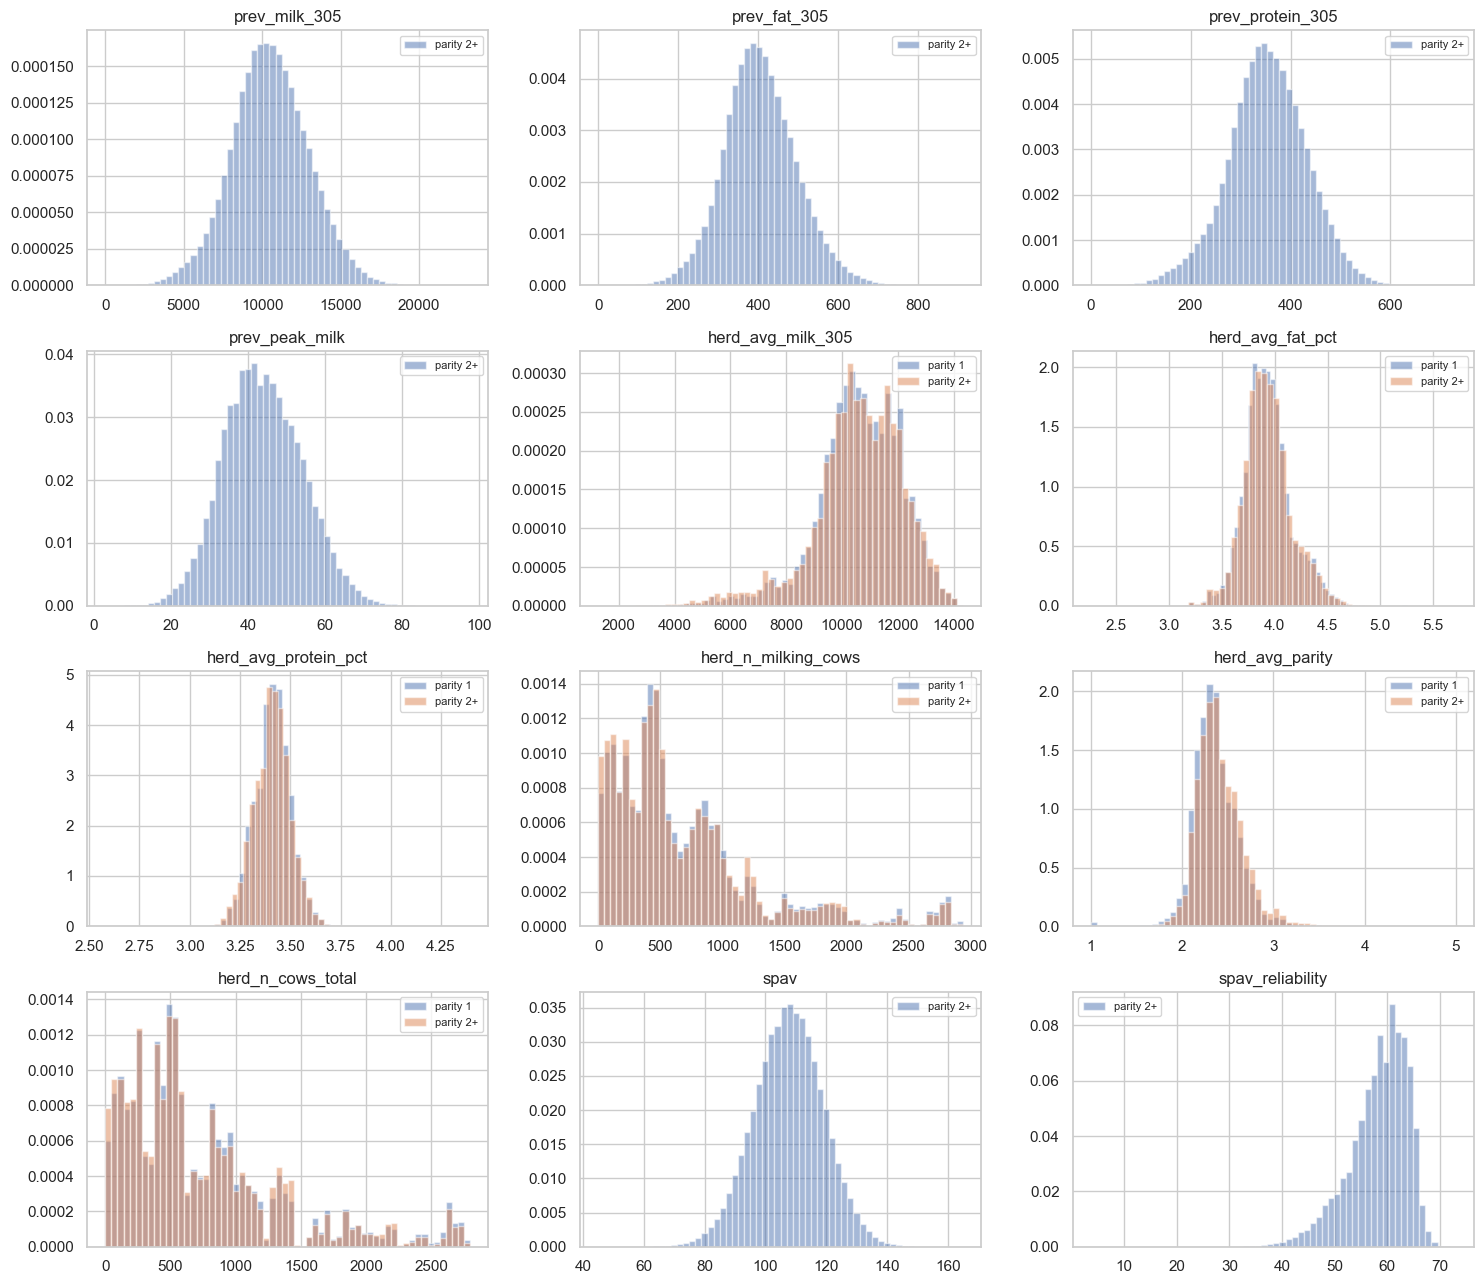

In [7]:
num_tunnused = [c for c in tunnused if c != "has_ebv"]

fig, axes = plt.subplots(4, 3, figsize=(15, 13))
axes = axes.ravel()
for ax, c in zip(axes, num_tunnused):
    for g, d in train.groupby("grupp"):
        if d[c].notna().sum() > 0:
            ax.hist(d[c].dropna(), bins=60, alpha=0.5, density=True, label=g)
    ax.set_title(c)
    ax.legend(fontsize=8)
for ax in axes[len(num_tunnused):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Mida näen jaotustest:**

Enamik tunnustest on ühemodaalsed. Eelnevast poegimisest mittesõltuvad tunnused on poegimata ja poeginute vahel sarnased, nii et selle mudeli tegemiseks, mis ennustab 1. aasta poegijatele stuffi, võib kasutada ka vastavaid andmeid varem poeginutelt.

Targetite jaotus, et oleks näha, millega võrdlen:

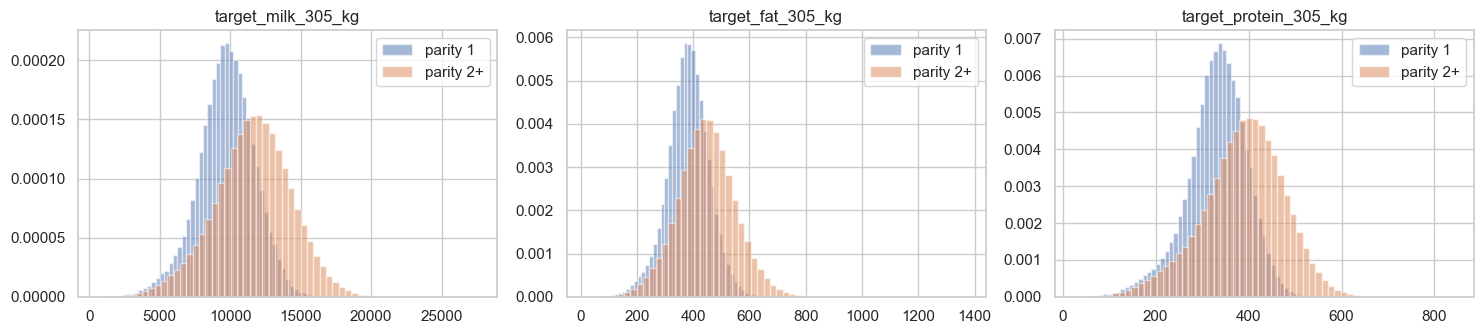

,target_milk_305_kg,target_fat_305_kg,target_protein_305_kg
grupp,,,
parity 1,9755.05,382.082095,334.826545
parity 2+,11688.25,446.932913,393.655683


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, t in zip(axes, targetid):
    for g, d in train.groupby("grupp"):
        ax.hist(d[t].dropna(), bins=60, alpha=0.5, density=True, label=g)
    ax.set_title(t)
    ax.legend()
plt.tight_layout()
plt.show()

train.groupby("grupp")[targetid].median()

**Mida näen:**

Pärast esimest poegimist on lehmade tootlus üldiselt suurem, aga väärtuste jaotus läheb ka laiemaks. parity 1 toodangud on üldiselt väiksemas vahemikus ja rohkem lehmi toodab keskmise lähedale.

## 3. Korrelatsioonid

Pearson näitab lineaarset seost, Spearman lihtsalt seda, kas üks kasvab koos teisega (ei pea olema sirge).

In [41]:
kor_p2 = pd.DataFrame({
    "pearson_milk": p2[tunnused].corrwith(p2["target_milk_305_kg"]),
    "spearman_milk": p2[tunnused].corrwith(p2["target_milk_305_kg"], method="spearman"),
    "pearson_fat": p2[tunnused].corrwith(p2["target_fat_305_kg"]),
    "spearman_fat": p2[tunnused].corrwith(p2["target_fat_305_kg"], method="spearman"),
    "pearson_protein": p2[tunnused].corrwith(p2["target_protein_305_kg"]),
    "spearman_protein": p2[tunnused].corrwith(p2["target_protein_305_kg"], method="spearman"),
}).sort_values("spearman_milk", ascending=False)
print("parity 2+")
kor_p2.round(3)

parity 2+


,pearson_milk,spearman_milk,pearson_fat,spearman_fat,pearson_protein,spearman_protein
prev_milk_305,0.676,0.654,0.529,0.505,0.628,0.600
prev_protein_305,0.657,0.628,0.574,0.549,0.670,0.638
herd_avg_milk_305,0.655,0.615,0.577,0.543,0.674,0.627
prev_peak_milk,0.565,0.537,0.437,0.411,0.517,0.485
prev_fat_305,0.550,0.527,0.640,0.626,0.571,0.549
spav,0.410,0.404,0.397,0.394,0.451,0.450
herd_n_milking_cows,0.332,0.384,0.309,0.356,0.337,0.392
herd_n_cows_total,0.328,0.365,0.307,0.344,0.333,0.375
has_ebv,0.122,0.095,0.103,0.083,0.102,0.072
spav_reliability,0.011,0.000,0.002,-0.010,-0.043,-0.056


In [42]:
kor_p1 = pd.DataFrame({
    "pearson_milk": p1[karja_tunnused].corrwith(p1["target_milk_305_kg"]),
    "spearman_milk": p1[karja_tunnused].corrwith(p1["target_milk_305_kg"], method="spearman"),
    "pearson_fat": p1[karja_tunnused].corrwith(p1["target_fat_305_kg"]),
    "spearman_fat": p1[karja_tunnused].corrwith(p1["target_fat_305_kg"], method="spearman"),
    "pearson_protein": p1[karja_tunnused].corrwith(p1["target_protein_305_kg"]),
    "spearman_protein": p1[karja_tunnused].corrwith(p1["target_protein_305_kg"], method="spearman"),
}).sort_values("spearman_milk", ascending=False)
print("parity 1")
kor_p1.round(3)

parity 1


,pearson_milk,spearman_milk,pearson_fat,spearman_fat,pearson_protein,spearman_protein
herd_avg_milk_305,0.607,0.559,0.561,0.510,0.633,0.575
herd_n_milking_cows,0.317,0.360,0.310,0.361,0.318,0.373
herd_n_cows_total,0.314,0.344,0.311,0.350,0.316,0.357
herd_avg_parity,-0.115,-0.071,-0.128,-0.088,-0.128,-0.072
herd_avg_protein_pct,-0.093,-0.124,-0.014,-0.032,0.001,-0.035
herd_avg_fat_pct,-0.261,-0.237,-0.086,-0.070,-0.248,-0.215


**Mida näen (millel on kõige tugevam seos, kas pearson ja spearman erinevad palju):**

Pearsoni ja spearmani kordajad on igal tunnudel üsna sarnased ehk siis kui eksisteerib korrelatsioon, siis see on valdavalt lineaarne. Suurimad mõjurid targetitele on eelmise aasta tulemused, ja herd_average_milk_305. herd_avg_protein mõjutab asju väga väga vähe. herd_avg_fat_pct üllatavalt mõjutab piima ja valgu tootlust rohkem kui rasva tootlust.

Korrelatsioonimaatriks, et näha ka seda, kui palju tunnused omavahel seotud on (parity 2+):

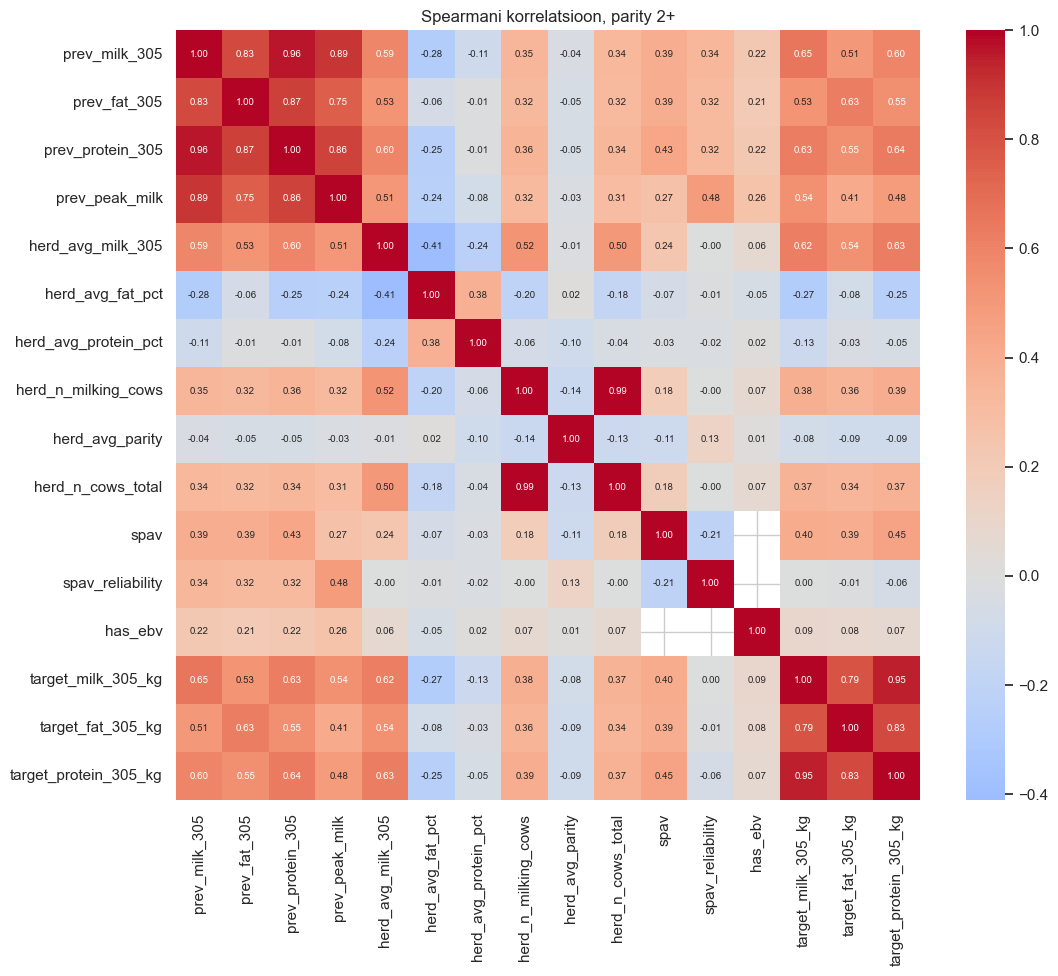

In [43]:
plt.figure(figsize=(12, 10))
sns.heatmap(p2[tunnused + targetid].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Spearmani korrelatsioon, parity 2+")
plt.show()

**Mida näen (mis tunnused on omavahel väga seotud, kas need kordavad üksteist):**

Kõige tihedamalt on omavahel seotud targetid ise ja eelmise aasta tulemused (kõige vähem on piima ja valgu toodanguga seotud rasvasisaldus aga korrelatsioon on siiski tugev). See tähendab, et meil ehk ei ole vaja ennustada eraldi piima ja valgu toodangut vaid nt piima ennustuse kaudu ennustada valgu ja mingil määral ka rasva. Äkki saaks teha mingi sellise kaskaadi, et ennustame piima, kasutame seda ennustust ka mudelis mis ennustab valku ja siis neid kahte tulemusi kasutame rasva ennustamiseks (lisaks muudele tunnustele).

## 4. Iga tunnus eraldi vs target

Kaks graafikut:
vasakul hexbin (värv näitab, kui palju punkte seal on), paremal jagan tunnuse 20 võrdse suurusega
vahemikku ja joonistan iga vahemiku keskmise targeti. 

In [12]:
def vahemike_keskmised(df, tunnus, t, n_bins=20):
    d = df[[tunnus, t]].dropna()
    if d[tunnus].nunique() <= n_bins:
        vahemik = d[tunnus]
    else:
        vahemik = pd.qcut(d[tunnus], n_bins, duplicates="drop")
    tulemus = d.groupby(vahemik, observed=True).agg(x=(tunnus, "mean"), y=(t, "mean"),
                                                    sd=(t, "std"), n=(t, "size"))
    return tulemus


def joonista(tunnus, t=target, grupid=("parity 2+",)):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    d = train[train["grupp"] == grupid[-1]][[tunnus, t]].dropna()
    lo, hi = d[tunnus].quantile([0.005, 0.995])
    d = d[(d[tunnus] >= lo) & (d[tunnus] <= hi)]
    hb = axes[0].hexbin(d[tunnus], d[t], gridsize=50, bins="log", mincnt=1, cmap="viridis")
    plt.colorbar(hb, ax=axes[0])
    axes[0].set_xlabel(tunnus)
    axes[0].set_ylabel(t)
    axes[0].set_title(grupid[-1])

    for g in grupid:
        k = vahemike_keskmised(train[train["grupp"] == g], tunnus, t)
        viga = 1.96 * k["sd"] / np.sqrt(k["n"])
        axes[1].errorbar(k["x"], k["y"], yerr=viga, marker="o", capsize=2, label=g)
    axes[1].set_xlabel(tunnus)
    axes[1].set_ylabel("keskmine " + t)
    axes[1].set_xlim(lo, hi)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

### 4.1 Eelmine laktatsioon (ainult parity 2+)

#### prev_milk_305

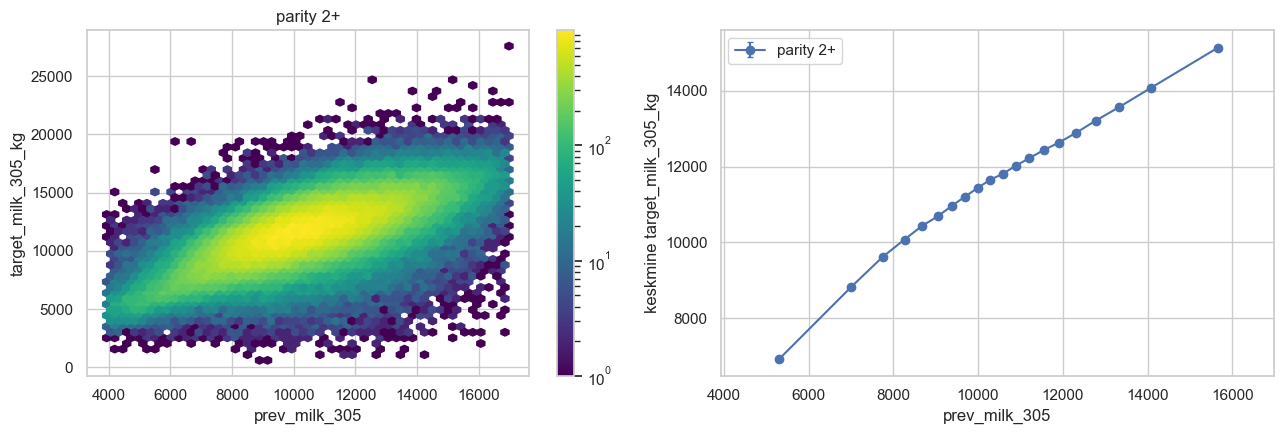

In [13]:
joonista("prev_milk_305")

**Mida näen:**

hea korrelatsioon, peaaegu lineaarne

#### prev_fat_305

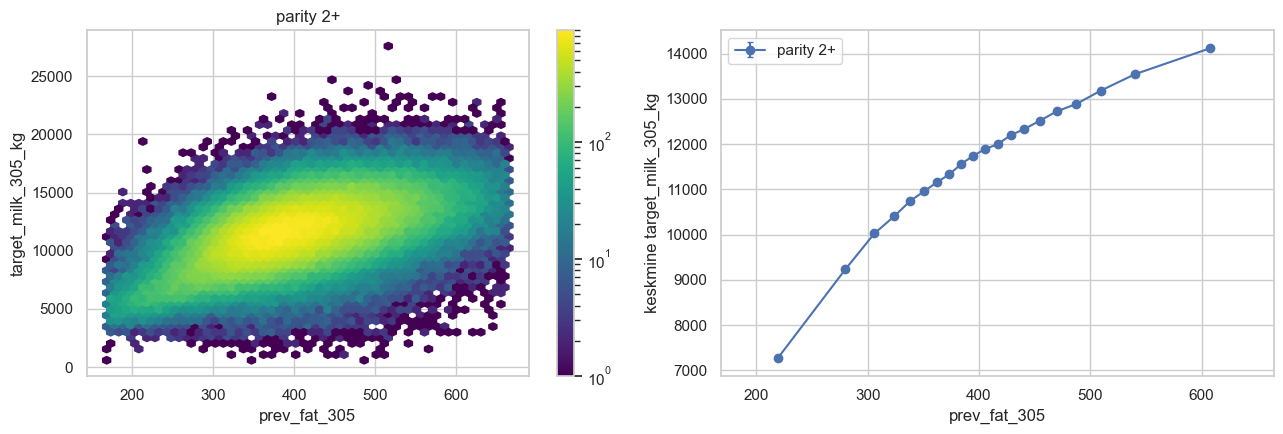

In [14]:
joonista("prev_fat_305")

**Mida näen:**

mittelineaarne aga ühtlane korrelatsioon eksisteerib

#### prev_protein_305

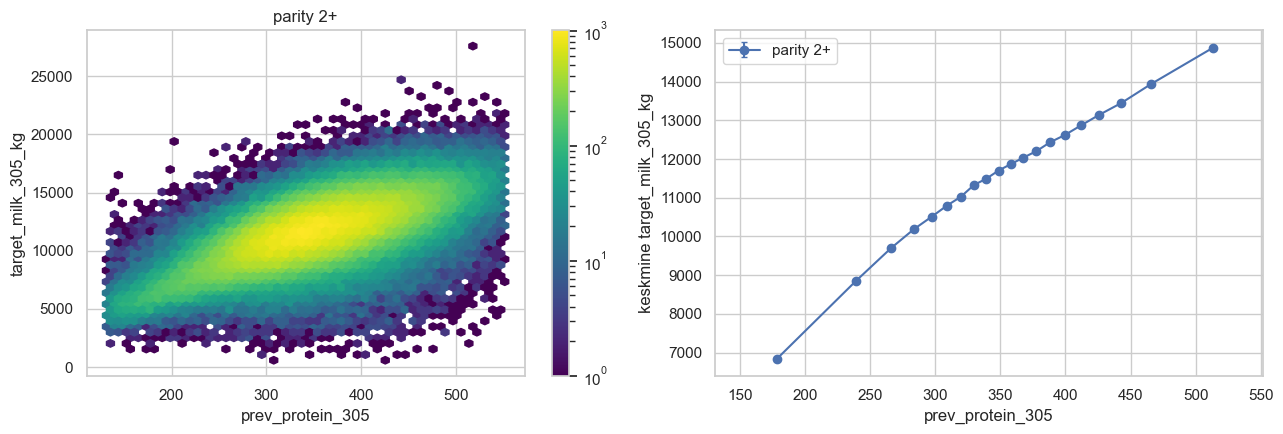

In [15]:
joonista("prev_protein_305")

**Mida näen:**

peaaegu lineaarne sõltuvus

#### prev_peak_milk

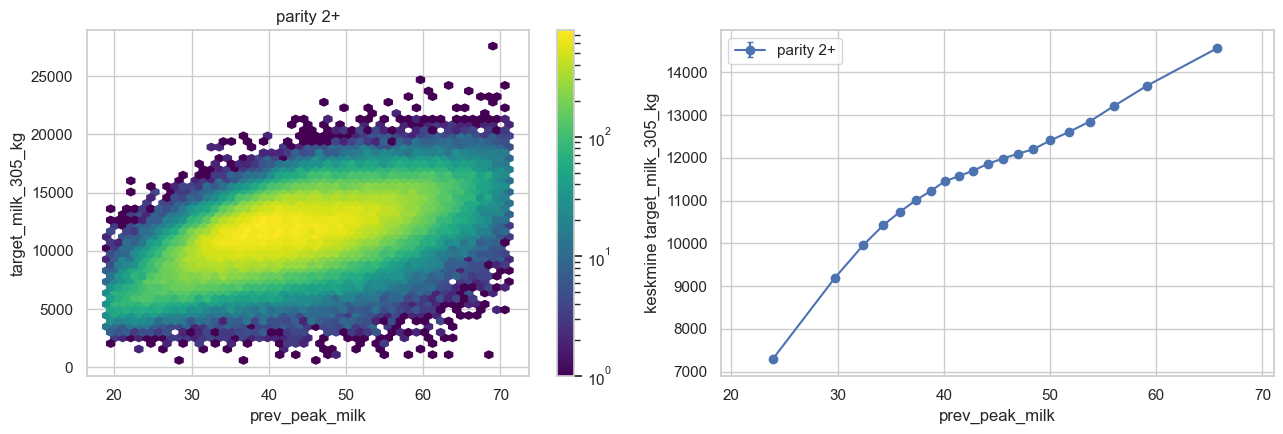

In [16]:
joonista("prev_peak_milk")

**Mida näen:**

sõltuvus on aga mittelineaarne

#### Sõltuvus targeti ja eelmise aasta piimatoodangu vahel

Sobitan sirge `target = a + b * prev_milk_305`. Kalle näitab Sama graafiku tõusu b iga parity puhul eraldi.

In [17]:
d = p2[["prev_milk_305", "target_milk_305_kg"]].dropna()
b, a = np.polyfit(d["prev_milk_305"], d["target_milk_305_kg"], 1)
print(f"target = {a:.0f} + {b:.3f} * prev_milk_305")

# kas see on eri parity puhul erinev?
for par in [2, 3, 4, 5]:
    dd = p2[p2["parity"].clip(upper=5) == par][["prev_milk_305", "target_milk_305_kg"]].dropna()
    b_, a_ = np.polyfit(dd["prev_milk_305"], dd["target_milk_305_kg"], 1)
    print(f"parity {par}{'+' if par == 5 else ''}: kalle {b_:.3f}  (n={len(dd)})")

target = 3733 + 0.750 * prev_milk_305
parity 2: kalle 0.942  (n=86382)
parity 3: kalle 0.828  (n=59961)
parity 4: kalle 0.816  (n=34364)
parity 5+: kalle 0.817  (n=29355)


#### Rasv ja valk oma targetiga

Rasva ja valgu puhul on loogilisem võrrelda eelmise aasta rasva tänavuse rasvaga.

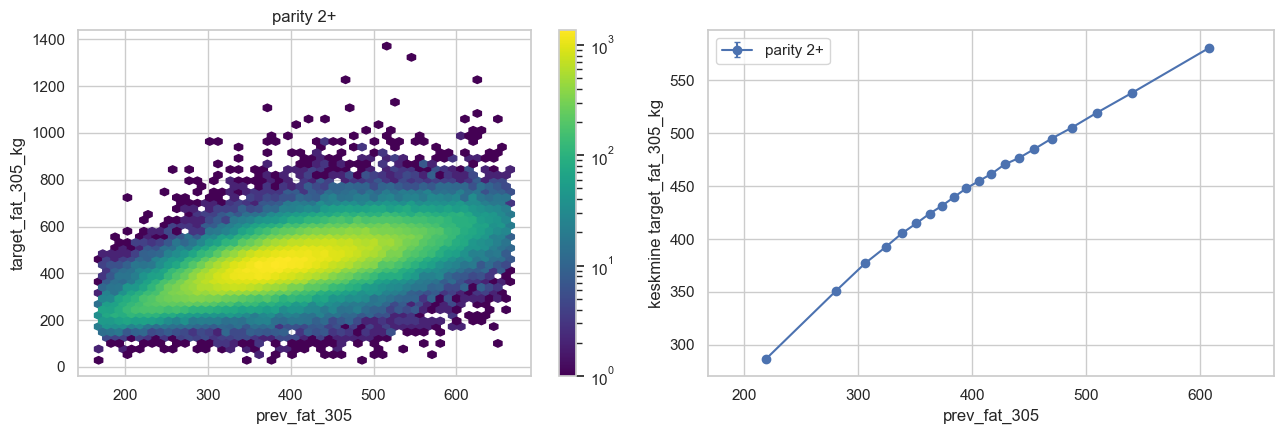

In [18]:
joonista("prev_fat_305", t="target_fat_305_kg")

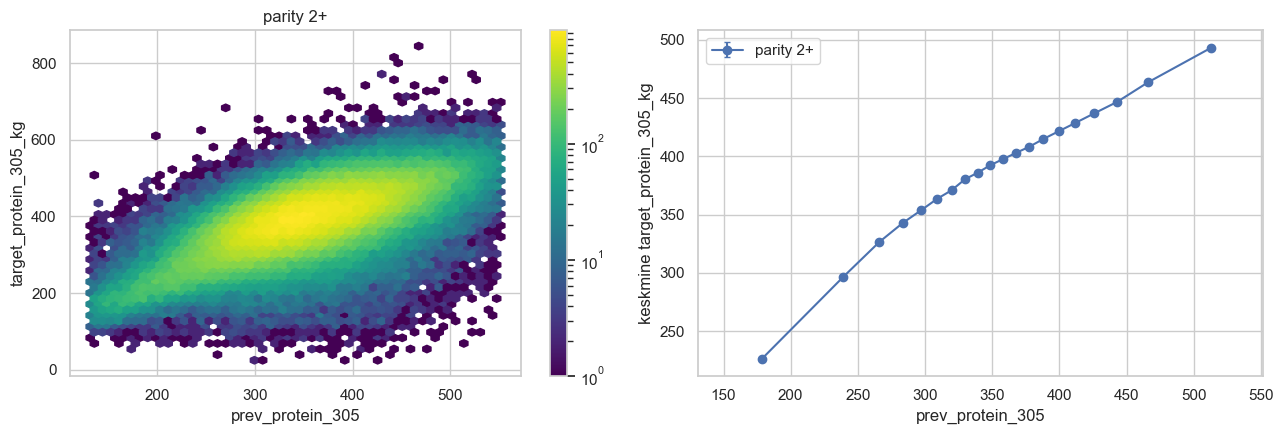

In [19]:
joonista("prev_protein_305", t="target_protein_305_kg")

**Mida näen:**

Mõlemal üuhul on positiivne mittelineaarne seos.

#### Omad tunnused: eelmise aasta rasva % ja valgu %

Kas lehm, kelle piimas oli eelmisel aastal kõrge rasva %, annab vähem piima?

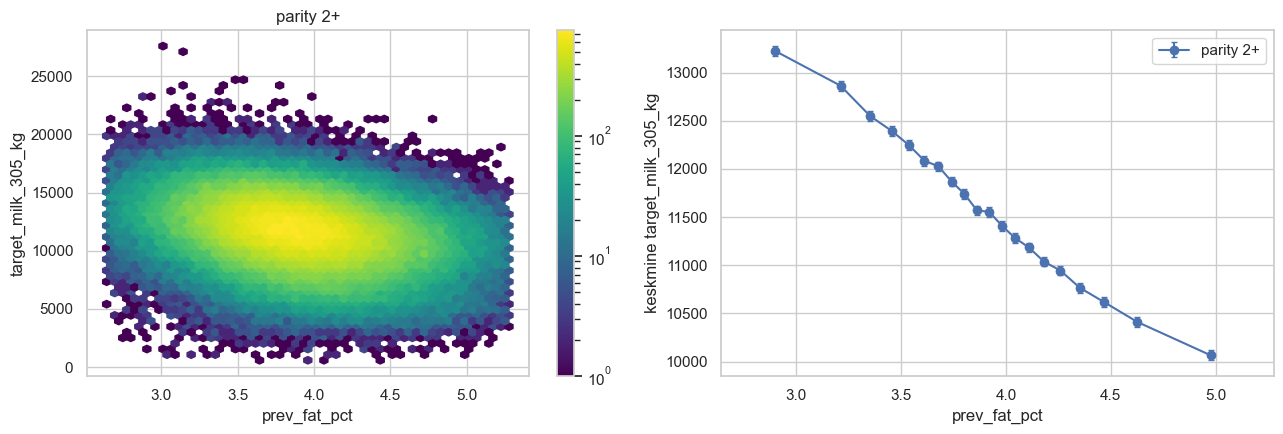

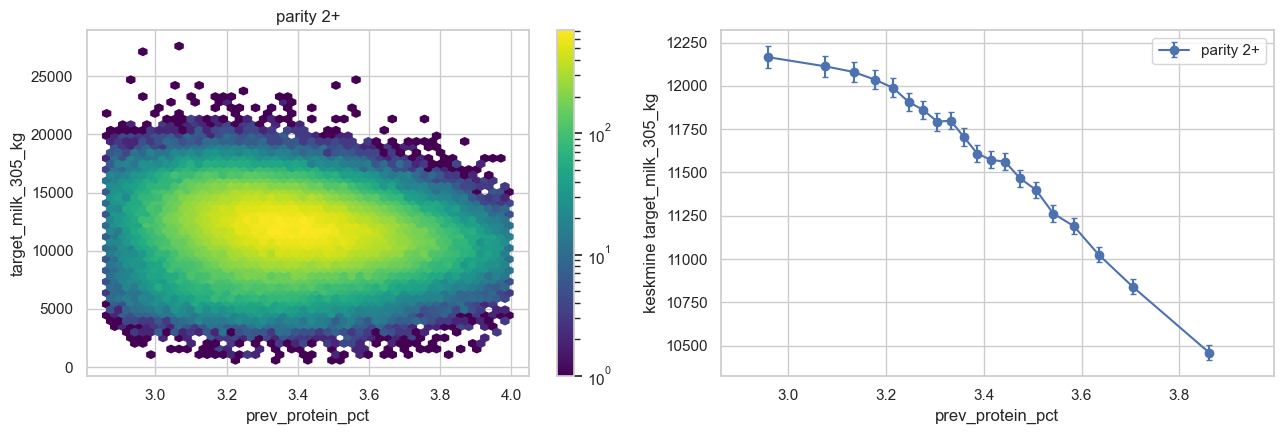

In [20]:
train["prev_fat_pct"] = train["prev_fat_305"] / train["prev_milk_305"] * 100
train["prev_protein_pct"] = train["prev_protein_305"] / train["prev_milk_305"] * 100
p2 = train[train["grupp"] == "parity 2+"]
joonista("prev_fat_pct")
joonista("prev_protein_pct")

**Mida näen:**

Graafikutel, kus alguses ei tundunud väga head korrelatsiooni, on tegelikult see täiesti olemas. Kui eelmisel aastal oli piimas rohkem valku või rasva, on piimatootlus järgmisel aasta väiksem.

### 4.2 Karja tunnused (mõlemad grupid)

#### herd_avg_milk_305

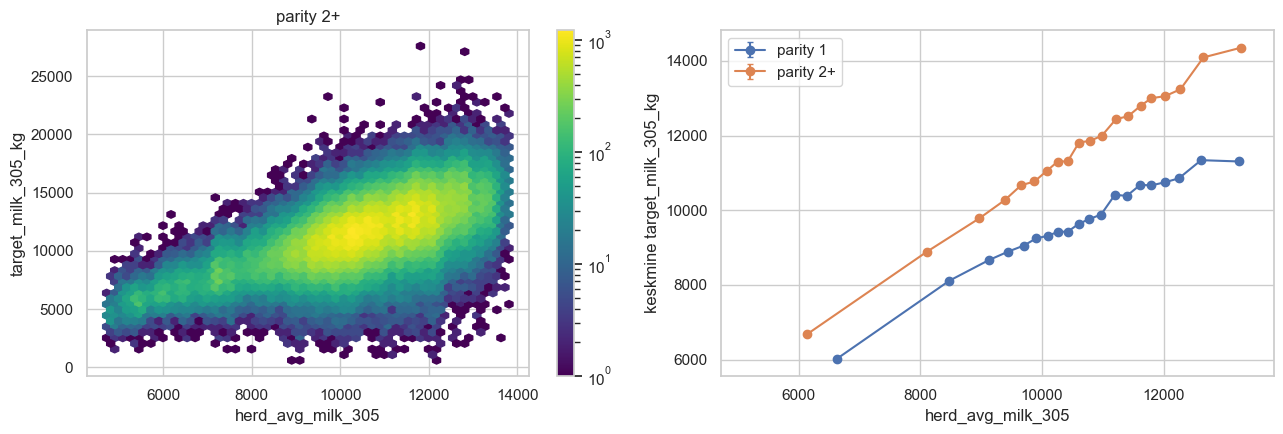

In [21]:
joonista("herd_avg_milk_305", grupid=("parity 1", "parity 2+"))

**Mida näen:**

Esimese aasta poegijad toodavad üldiselt vähem piima. Mõlema grupi puhul kehtib enamvähem terves graafiku ulatuses see, et kui karja piimatoodang on suurem, siis on ka piima toodang sellel aastal suurem.

#### herd_avg_fat_pct

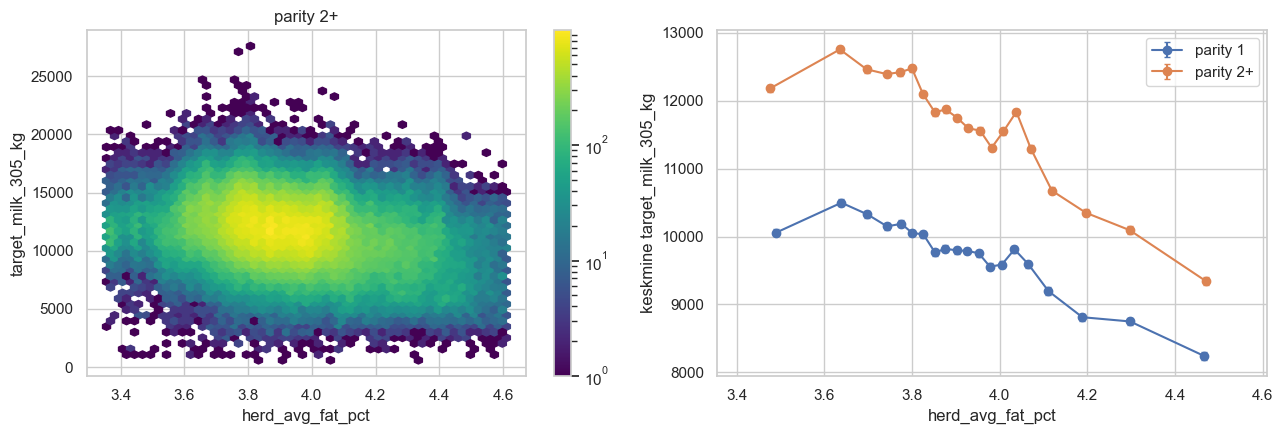

In [22]:
joonista("herd_avg_fat_pct", grupid=("parity 1", "parity 2+"))

**Mida näen:**

Gruppide trendid on sarnased ehk see, kuidas karja keskmised rasvasisaldused mõjutavad piimatoodangut, on sarnase tõusuga. Jälle on näha, kuidas esmapoegijate toodang on palju madalam kui teistel

#### herd_avg_protein_pct

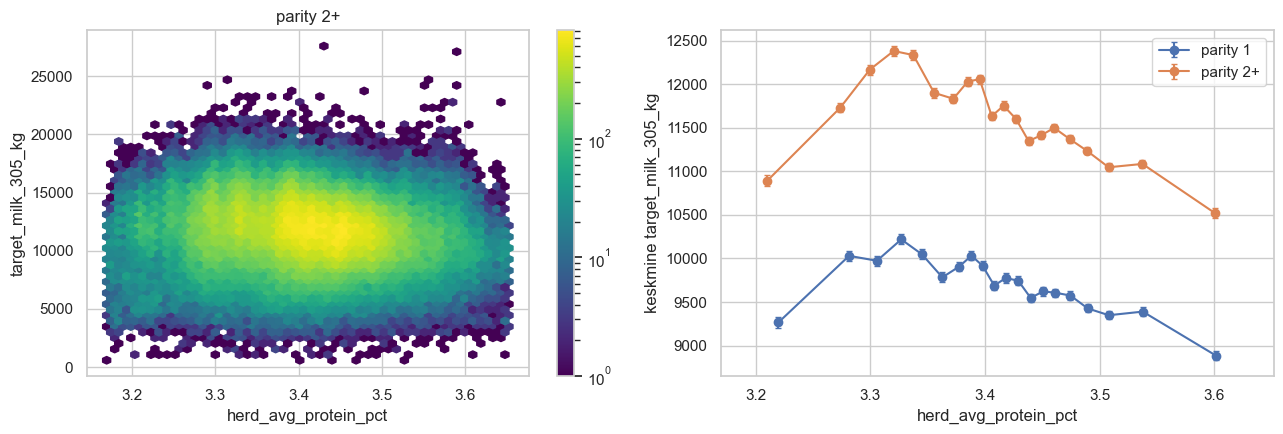

In [23]:
joonista("herd_avg_protein_pct", grupid=("parity 1", "parity 2+"))

**Mida näen:**

Graafik on lineaarne umbes vahemikus 3.31...3.6. Trendid jällegi samasugused mõlemal grupil

#### herd_n_milking_cows

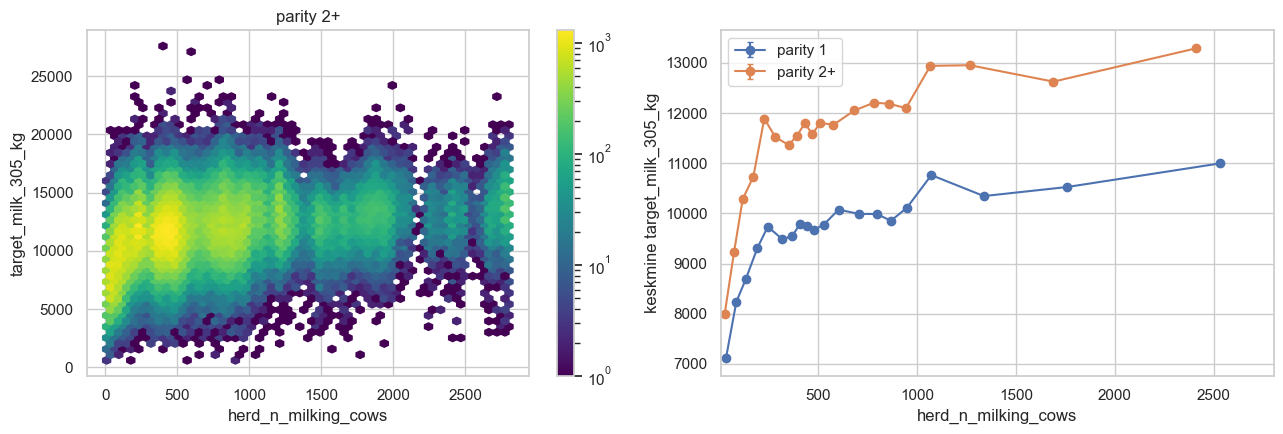

In [24]:
joonista("herd_n_milking_cows", grupid=("parity 1", "parity 2+"))

**Mida näen:**

target milk on karja piimatootjate arvust sõltuv eksponentsiaalselt (?)

#### herd_avg_parity

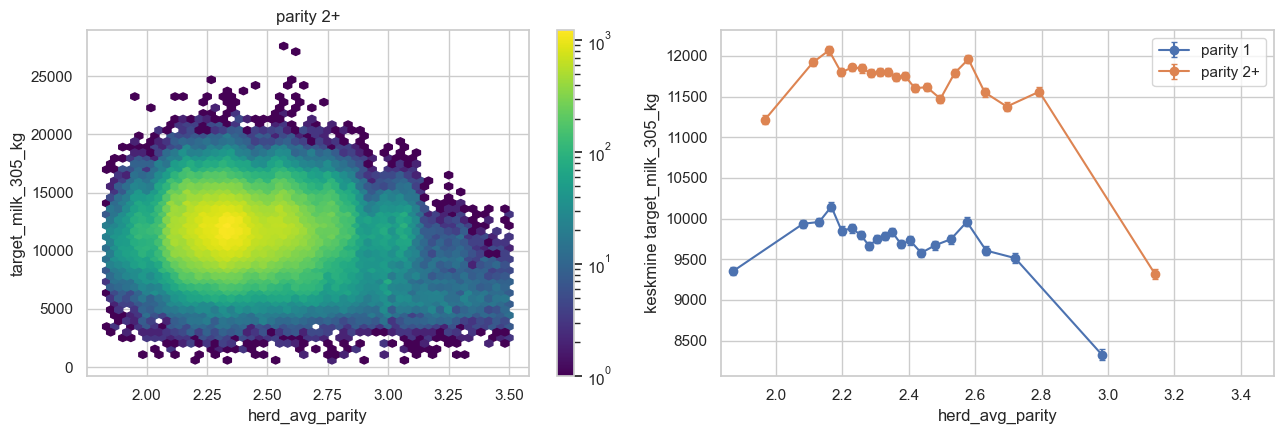

In [25]:
joonista("herd_avg_parity", grupid=("parity 1", "parity 2+"))

**Mida näen:**

Ka siin on näha üsna korralikku mittelineaarset trendi tunnuste vahel

#### herd_n_cows_total

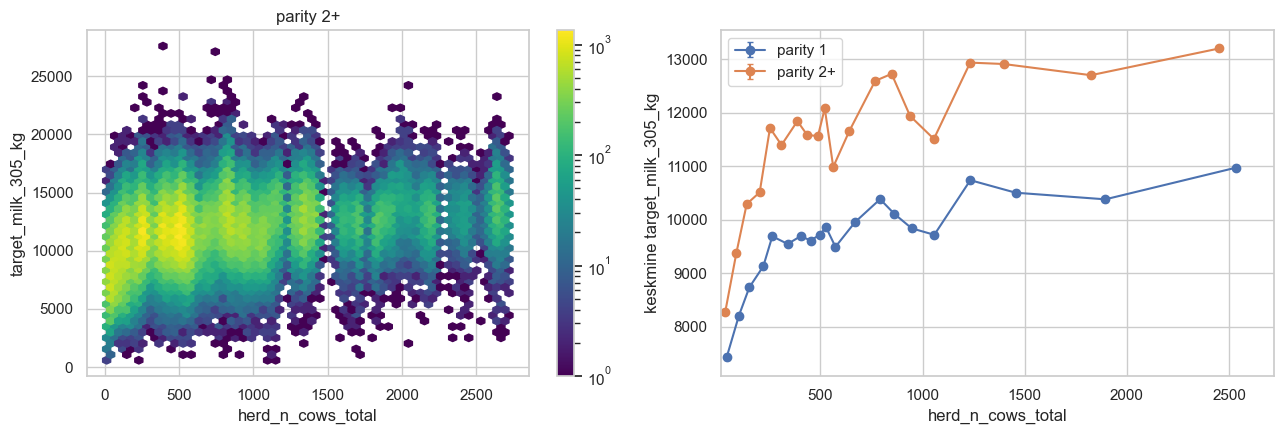

In [26]:
joonista("herd_n_cows_total", grupid=("parity 1", "parity 2+"))

**Mida näen:**

Taaskord eksponentsiaalne tõus

#### Karja keskmine vs karja tegelik keskmine

Kasutan `herd_id`, et arvutada iga karja tegelik keskmine target ja võrrelda seda `herd_avg_milk_305` keskmisega.
Kui punktid on joone y = x peal, siis karja keskmine ennustab karja taset hästi.

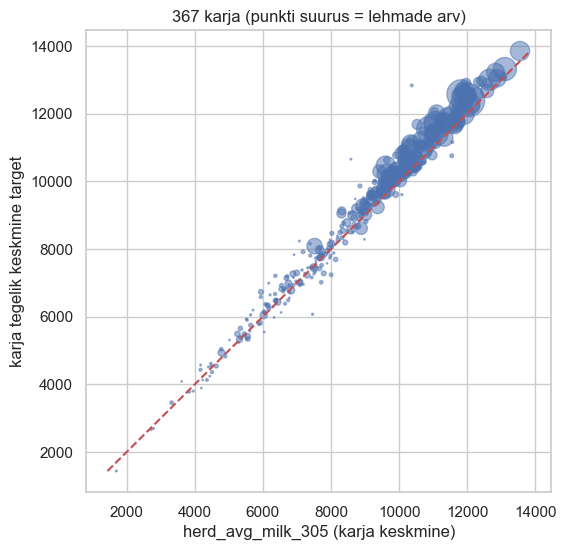

korrelatsioon karjade tasemel: 0.989


In [27]:
karjad = train.groupby("herd_id").agg(herd_avg=("herd_avg_milk_305", "mean"),
                                       tegelik=("target_milk_305_kg", "mean"),
                                       n=("target_milk_305_kg", "size"))
karjad = karjad[karjad["n"] >= 20]

plt.figure(figsize=(6, 6))
plt.scatter(karjad["herd_avg"], karjad["tegelik"], s=karjad["n"] / 20, alpha=0.5)
lim = [karjad[["herd_avg", "tegelik"]].min().min(), karjad[["herd_avg", "tegelik"]].max().max()]
plt.plot(lim, lim, "r--")
plt.xlabel("herd_avg_milk_305 (karja keskmine)")
plt.ylabel("karja tegelik keskmine target")
plt.title(f"{len(karjad)} karja (punkti suurus = lehmade arv)")
plt.show()
print("korrelatsioon karjade tasemel:", round(karjad["herd_avg"].corr(karjad["tegelik"]), 3))

**Mida näen:**

Karja keskmine kirjeldab tegelikku olukorda väga hästi.

#### Rasva ja valgu % karjas vs rasva ja valgu target

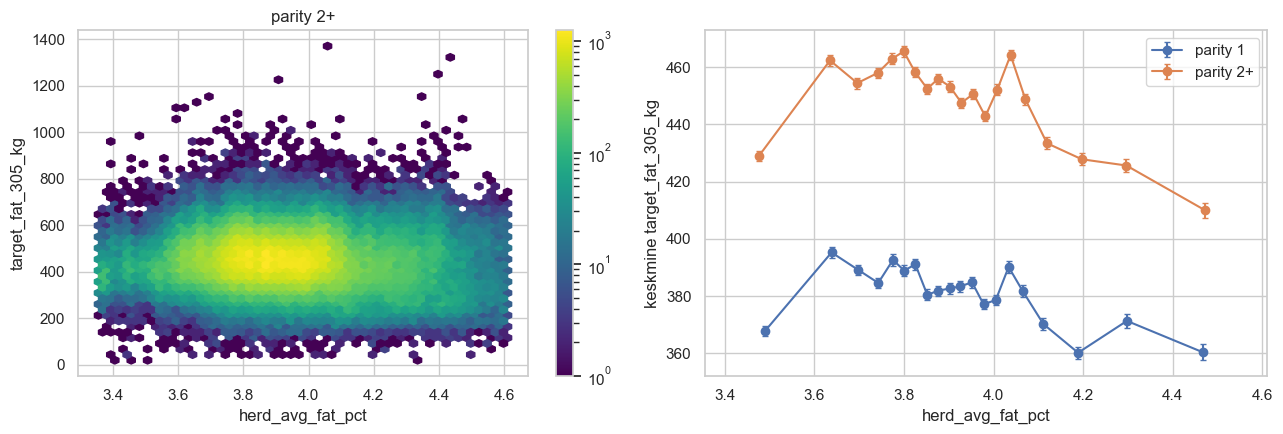

In [28]:
joonista("herd_avg_fat_pct", t="target_fat_305_kg", grupid=("parity 1", "parity 2+"))

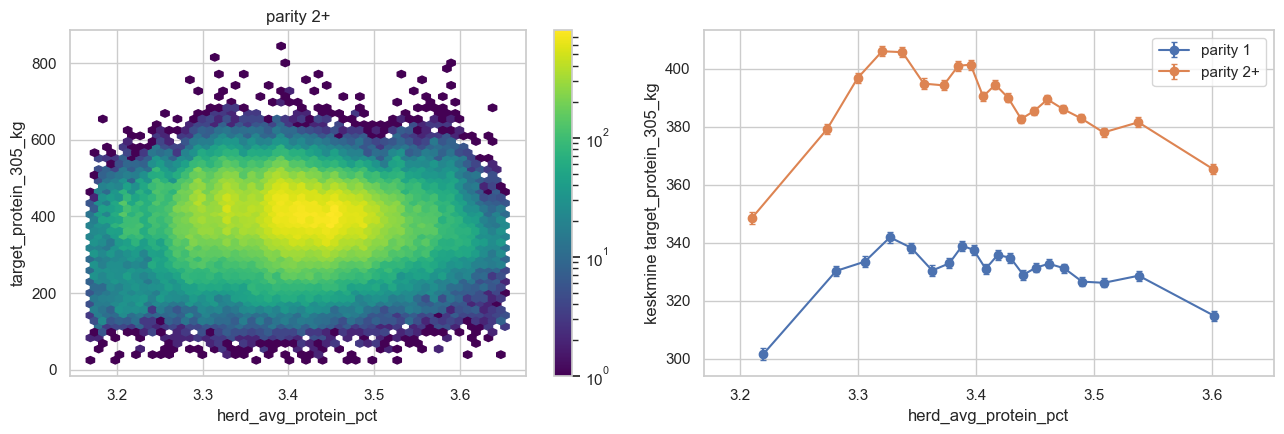

In [29]:
joonista("herd_avg_protein_pct", t="target_protein_305_kg", grupid=("parity 1", "parity 2+"))

### 4.3 Aretusväärtus (ainult parity 2+)

#### spav

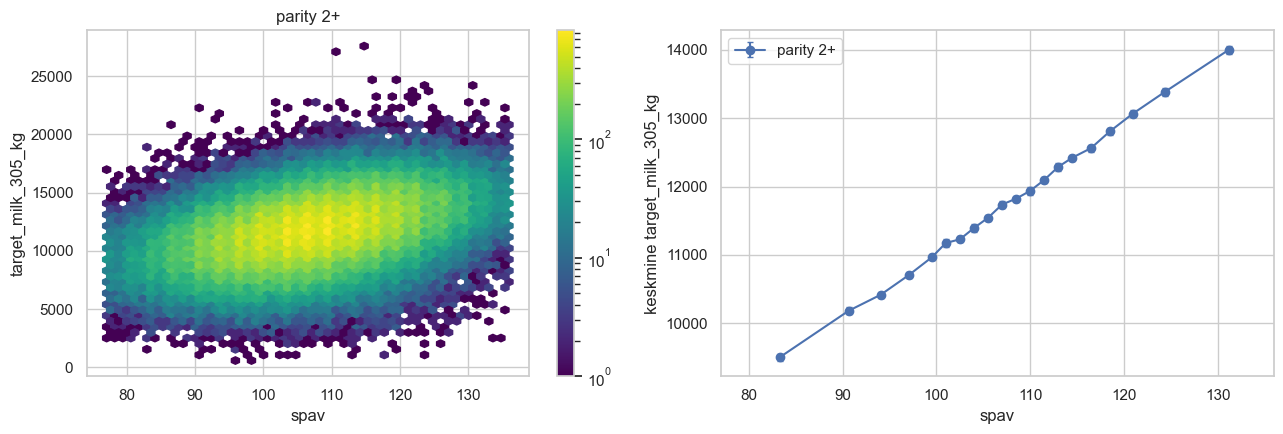

In [30]:
joonista("spav")

**Mida näen:**

Spav on ilmselt arvutatud selle sama sirge pealt, mida me näeme.

#### spav_reliability

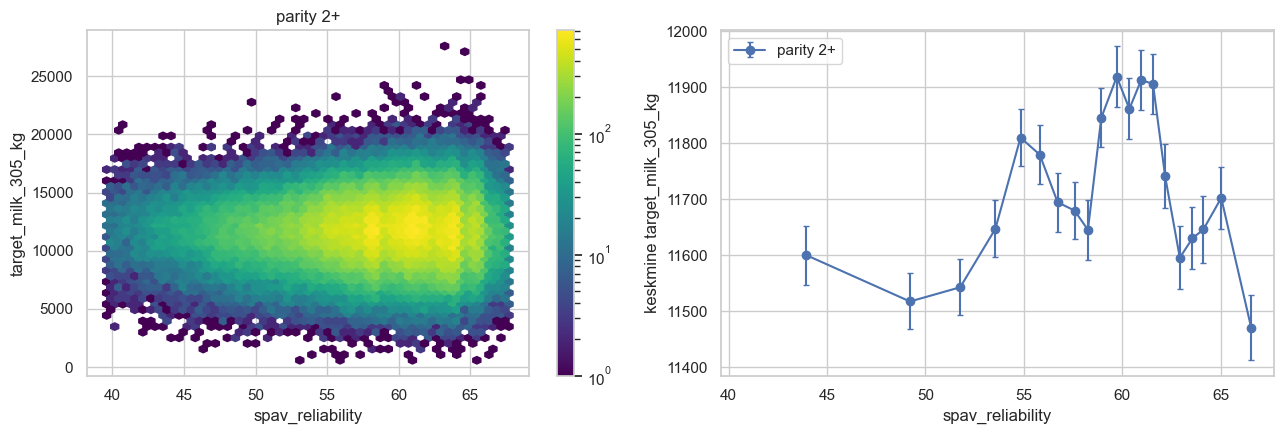

In [31]:
joonista("spav_reliability")

**Mida näen:**

See ütleb piimatoodangu kohta väga vähe.

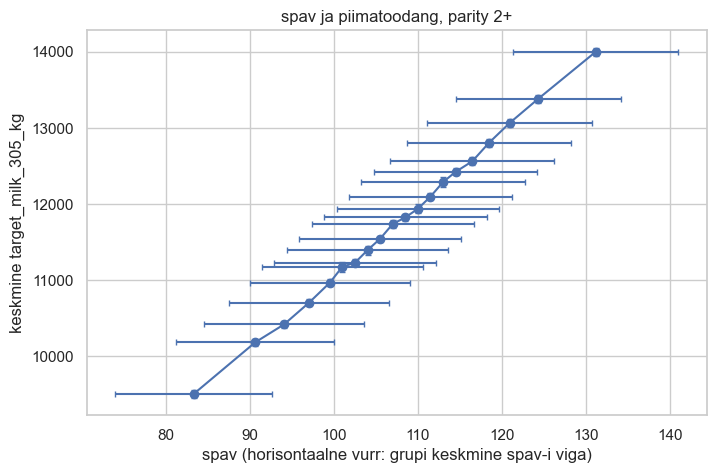

In [46]:
d = p2[["spav", "spav_reliability", "target_milk_305_kg"]].dropna().copy()

# spav-i viga iga lehma kohta: sd_g * sqrt(1 - reliability)
rel = d["spav_reliability"] / 100
sd_g = d["spav"].std() / np.sqrt(rel.mean())   # hinnang andmetest, täpset väärtust ei tea
d["spav_viga"] = sd_g * np.sqrt(1 - rel)

# samad 20 gruppi nagu joonista funktsioonis
d["vahemik"] = pd.qcut(d["spav"], 20, duplicates="drop")
k = d.groupby("vahemik", observed=True).agg(
    spav_keskm=("spav", "mean"),
    spav_viga=("spav_viga", "mean"),        # grupi lehmade keskmine spav-i viga
    rel_keskm=("spav_reliability", "mean"),
    y=("target_milk_305_kg", "mean"),
    sd=("target_milk_305_kg", "std"),
    n=("target_milk_305_kg", "size"),
)
k["y_viga"] = 1.96 * k["sd"] / np.sqrt(k["n"])   # sama nagu joonista funktsioonis

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(k["spav_keskm"], k["y"], xerr=k["spav_viga"], yerr=k["y_viga"],
            marker="o", capsize=2)
ax.set_xlabel("spav (horisontaalne vurr: grupi keskmine spav-i viga)")
ax.set_ylabel("keskmine target_milk_305_kg")
ax.set_title("spav ja piimatoodang, parity 2+")
plt.show()


#### has_ebv

Kas lehmad, kellel aretusväärtust pole, toodavad teistsuguselt? Vaatan ainult parity 2+.

        target_milk_305_kg                  target_fat_305_kg                 \
                      mean   median   count              mean median   count   
has_ebv                                                                        
0.0                10653.0  11059.0   23476             418.0  428.0   23476   
1.0                11709.0  11757.0  186628             451.0  449.0  186628   

        target_protein_305_kg                 
                         mean median   count  
has_ebv                                       
0.0                     362.0  380.0   23476  
1.0                     391.0  395.0  186628  


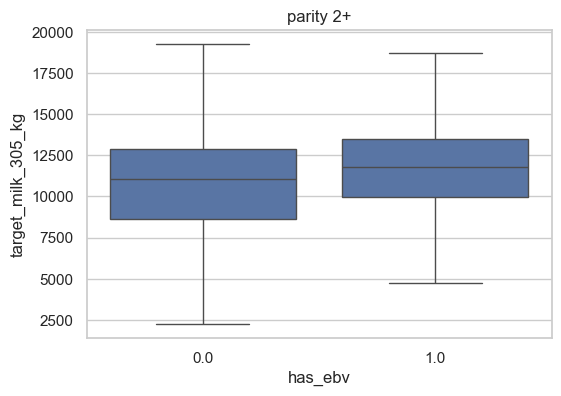

In [32]:
print(p2.groupby("has_ebv")[targetid].agg(["mean", "median", "count"]).round(0))

plt.figure(figsize=(6, 4))
sns.boxplot(data=p2, x="has_ebv", y=target, showfliers=False)
plt.title("parity 2+")
plt.show()

**Mida näen:**

Neil, kellel on ebv, on target milk rohkem koondunud. Keskmine väärtus tegelikult väga ei erine

## 5. Kaks tunnust koos

Kas ühe tunnuse mõju sõltub teisest? Jagan mõlemad tunnused vahemikeks ja teen tabeli, kus igas lahtris on keskmine target.

In [47]:
def kahe_tunnuse_tabel(df, t1, t2, n1=10, n2=10, t=target):
    d = df[[t1, t2, t]].dropna().copy()
    d["v1"] = pd.qcut(d[t1], n1, duplicates="drop")
    d["v2"] = pd.qcut(d[t2], n2, duplicates="drop")
    tabel = d.pivot_table(index="v1", columns="v2", values=t, aggfunc="mean", observed=True)
    plt.figure(figsize=(9, 5))
    sns.heatmap(tabel, annot=True, fmt=".0f", cmap="viridis")
    plt.xlabel(t2)
    plt.ylabel(t1)
    plt.title("keskmine " + t)
    plt.show()

#### prev_milk_305 ja herd_avg_milk_305

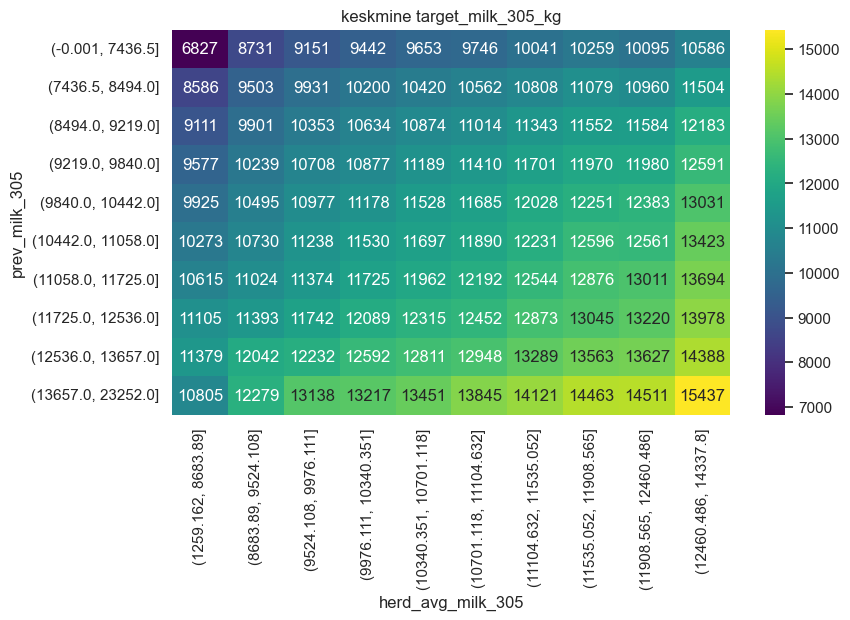

In [48]:
kahe_tunnuse_tabel(p2, "prev_milk_305", "herd_avg_milk_305")

**Mida näen:**

Mõlemad tunnused ennustavad targetit iseseisvalt.

#### prev_milk_305 ja spav

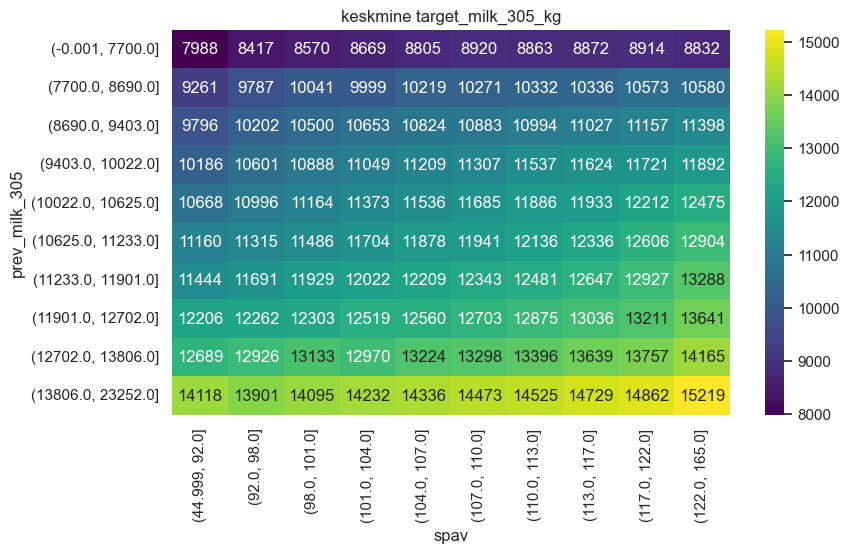

In [49]:
kahe_tunnuse_tabel(p2, "prev_milk_305", "spav")

**Mida näen:**

Mõlemad tunnused annavad lisainfot, prev milk annab lihtsalt rohkem infot

#### spav ja spav_reliability

Kas spav mõjutab rohkem, kui selle usaldusväärsus on kõrgem? Jagan reliability kolmeks grupiks.

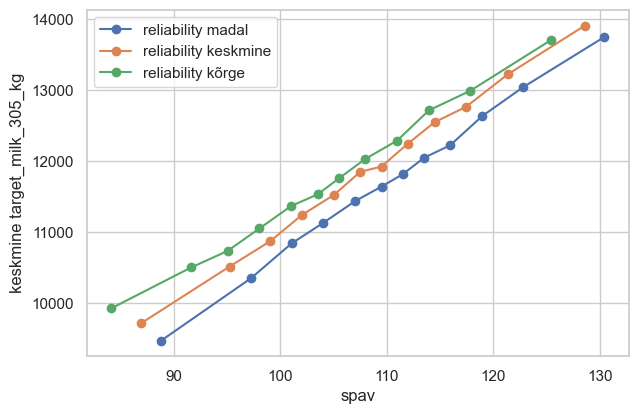

In [36]:
d = p2[["spav", "spav_reliability", target]].dropna().copy()
d["rel_grupp"] = pd.qcut(d["spav_reliability"], 3, labels=["madal", "keskmine", "kõrge"])

plt.figure(figsize=(7, 4.5))
for g, dd in d.groupby("rel_grupp", observed=True):
    k = vahemike_keskmised(dd, "spav", target, n_bins=12)
    plt.plot(k["x"], k["y"], marker="o", label=f"reliability {g}")
plt.xlabel("spav")
plt.ylabel("keskmine " + target)
plt.legend()
plt.show()

In [50]:
p2.assign(rel_grupp=pd.qcut(p2["spav_reliability"], 3, labels=["madal", "keskmine", "kõrge"])) \
  .groupby("rel_grupp", observed=True)[["parity", "prev_milk_305", "herd_avg_milk_305"]].mean().round(1)

,parity,prev_milk_305,herd_avg_milk_305
rel_grupp,,,
madal,2.1,9668.2,10691.3
keskmine,2.9,10898.1,10610.0
kõrge,4.6,11520.7,10655.6


**Mida näen:**

Joonte tõus on kõigi variantide puhul samasugune. Nihet seletab see, et kõrgema spav-ga (ja seetõttu ka kõrgema toodanguga) lehmadel on ka suurem spav reliability. Seega võime öelda, et spav ei mõjuta toodangut rohkem kui selle usaldusväärsus on suurem.

## 6. Kokkuvõte

Tugevus on Spearmani korrelatsioon `target_milk_305_kg`-ga (parity 2+, karja tunnustel sulgudes parity 1). Umbkaudne skaala: alla 0,1 seost pole, 0,1–0,3 nõrk, 0,3–0,5 keskmine, üle 0,5 tugev.

| tunnus | seose suund | kuju (sirge / kõver / lävi) | kui tugev | märkused |
|---|---|---|---|---|
| prev_milk_305 | + | peaaegu sirge | tugev (0,65) | kalle kõik koos 0,75, parity 2 0,94, parity 3–5+ umbes 0,82 |
| prev_fat_305 | + | kõver, kõrgetel väärtustel lameneb | tugev (0,53; rasva targetiga 0,63) | rasva targeti jaoks kõige tugevam tunnus; prev_milk-iga 0,83 |
| prev_protein_305 | + | peaaegu sirge | tugev (0,63; valgu targetiga 0,64) | prev_milk-iga 0,96, kordab seda peaaegu täielikult |
| prev_peak_milk | + | kõver: järsk tõus kuni umbes 35 kg, siis laugem | tugev (0,54) | prev_milk-iga 0,89 |
| herd_avg_milk_305 | + | sirge | tugev (0,62; parity 1: 0,56) | mõlemas grupis sama kuju; karjade tasemel korrelatsioon tegeliku keskmisega 0,989; annab infot ka prev_milk-i kõrval |
| herd_avg_fat_pct | − | kõver, üle umbes 4,0% langeb kiiremini | nõrk (−0,27; parity 1: −0,24) | piima ja valguga tugevam seos kui rasvaga (−0,08); herd_avg_milk-iga −0,41, osa seosest võib tulla sellest |
| herd_avg_protein_pct | − | küür: tõus kuni umbes 3,3%, siis langus | väga nõrk (−0,13; parity 1: −0,12) | |
| herd_n_milking_cows | + | kõver: järsk tõus kuni umbes 250 lehmani, siis peaaegu lame | keskmine (0,38; parity 1: 0,36) | min väärtus 0 lehma, kahtlane; herd_n_cows_total-iga 0,99 |
| herd_avg_parity | − äärtes | küür, langus üle umbes 2,7 | väga nõrk (−0,08; parity 1: −0,07) | äärtes vähe karju, keskel peaaegu tasane |
| herd_n_cows_total | + | sama nagu herd_n_milking_cows | keskmine (0,37; parity 1: 0,34) | kordab herd_n_milking_cows-i |
| spav | + | sirge | keskmine (0,40; valguga 0,45) | üksi umbes 100 kg spav-i punkti kohta, prev_milk-i kõrval umbes 50 kg; puudub kõigil parity 1 lehmadel ja 11% parity 2+ lehmadest |
| spav_reliability | puudub | – | puudub (0,00) | spav-i kallet ei muuda; kõrge reliability grupis on lehmad vanemad (keskmine parity 4,6 vs 2,1) ja kõrgema prev_milk-iga; spav-iga −0,21 |
| has_ebv | + | 0/1 | nõrk (0,09) | ilma EBV-ta lehmadel keskmine 10 653 vs 11 709 kg (umbes 1050 kg vähem), mediaan umbes 700 kg vähem, hajuvus suurem |

**Järeldused:**

- mis tunnused kindlasti sisse: `prev_milk_305`, `herd_avg_milk_305`, `spav` (koos `has_ebv`-ga, et puudumine oleks märgitud), `herd_n_milking_cows`. Rasva ja valgu ennustamiseks ka `prev_fat_305` ja `prev_protein_305`. Tuletatud `prev_fat_pct` ja `prev_protein_pct` tasub proovida, sest kõrgem rasva või valgu % tähendab järgmisel aastal väiksemat piimatoodangut (prooviks koos ja ilma selleta ja vaataks kas parandab tulemusi).
- mis tunnused kordavad üksteist: `prev_milk_305` ja `prev_protein_305` (0,96), `prev_peak_milk` (0,89) ja `prev_fat_305` (0,83) on kõik prev_milk-iga väga seotud. `herd_n_milking_cows` ja `herd_n_cows_total` (0,99), neist piisab ühest. `spav_reliability` üksi ei anna toodangu kohta infot.
- kas teha parity 1 ja 2+ jaoks eraldi mudel: jah. Parity 1 lehmadel puuduvad eelmise laktatsiooni tunnused ja spav täielikult, nende toodangu tase on madalam (mediaan 9755 vs 11 688 kg) ja jaotus kitsam. Karja tunnuste seosed on mõlemas grupis sama kujuga, nii et neid saab kasutada mõlemas mudelis. Parity 2+ mudelis peaks parity ise olema tunnus, sest prev_milk-i kalle on parity 2 puhul suurem (0,94) kui vanematel (umbes 0,82).
- mida veel proovida:
  - `prev_milk_305` suhtena karja keskmisesse (`prev_milk_305 / herd_avg_milk_305`), et lahutada lehma ja karja mõju. Lehmad parema toodanguga karjades toodavadki rohkem, aga selle suhtega me näeks kui hea on vastav lehm selles karjas);
  - karja suuruse logaritm, sest seos on kõver ja lameneb (ilusa sirge graafiku saamiseks, kas illustreerimiseks või lineaarse regressiooni rakendamiseks);
  - kaskaad: ennustada kõigepealt piim ja kasutada seda valgu ja rasva ennustamisel (target-ite omavaheline korrelatsioon on 0,79–0,95);